# Knowledge Tracing on ASSISTments: DKT vs SAKT vs AKT

**The idea in one paragraph.** A student works through a sequence of exercises, each tagged with a skill, and gets each one right or wrong. After every answer we want to guess: *how likely is this student to get the next exercise right?* That guess is a running estimate of what the student actually knows, which is the whole point of **knowledge tracing (KT)**. Tutoring systems use it to decide what to show next and when a student has mastered a skill.

This notebook trains three neural KT families on the ASSISTments 2009 *skill builder* data under **one identical protocol** and compares them honestly.

| Model | Core idea (intuition) | Reference |
|---|---|---|
| **DKT** (LSTM / GRU / plain RNN) | A recurrent network reads the history one step at a time and keeps a single running "knowledge state" vector. Run with three different recurrent cells. | Piech et al., 2015 |
| **SAKT** | No running state. For the next question, *look back* over all past interactions and attend to the ones that matter. | Pandey & Karypis, 2019 |
| **AKT (no Rasch)** | Full AKT architecture (question encoder, knowledge encoder, knowledge retriever, context-aware monotonic attention) using skill embeddings only. | Ghosh et al., 2020 |
| **AKT** | The above **plus a learned Rasch difficulty for every individual question**, so getting a hard question right counts for more than getting an easy one right. | Ghosh et al., 2020 |

Two pairs are run as ablations so each gap isolates one idea: SAKT **without / with** positional embeddings (what is *order* worth?), and AKT **without / with** Rasch question difficulty (what is *difficulty* worth?). DKT is also run with three recurrent cells, **LSTM / GRU / plain RNN**, to see how much the choice of memory cell matters.

### How the notebook is organised
1. Setup and configuration
2. Data loading and cleaning (with a row-count funnel)
3. Splits and sequence windows (by student, train / val / test)
4. Batching and the token encoding (with a worked example)
5. Model definitions
6. Training engine (one loop shared by all models)
7. Run all experiments
8. Results: tables and plots
9. How to read the results, limitations, next steps
10. References

### Protocol decisions that matter
- **Split by student, not by interaction.** The test set contains students the model has never seen.
- **Three-way split.** Train fits weights. Validation picks the best epoch. **Test is used once at the end.** (Picking the best epoch on the same data you report is optimistic.)
- **Same seed, same batch order for every model**, so differences come from the architecture, not luck of the draw.

## 1. The task, precisely

**Intuition first.** Think of each interaction as one tiny fact: *"student answered a skill-$s$ question and got it right (or wrong)"*. Given everything the student did so far, plus the skill of the question they're about to see, output a probability that they answer it correctly.

**Formally.** For a student with interactions $(s_1, c_1), \dots, (s_T, c_T)$, where $s_t \in \{0,\dots,N-1\}$ is the skill and $c_t \in \{0,1\}$ is correctness, the model predicts

$$\hat{p}_{t+1} = P\big(c_{t+1}=1 \mid (s_1,c_1),\dots,(s_t,c_t),\, s_{t+1}\big).$$

**One-number encoding of an interaction.** Embedding layers want a single integer, so each interaction becomes one token:

$$x_t = s_t + N \cdot c_t \in \{0,\dots,2N-1\}$$

Tokens $0..N-1$ mean "skill $s$, answered wrong"; tokens $N..2N-1$ mean "skill $s$, answered right".

**Training signal.** Binary cross-entropy between $\hat{p}_{t+1}$ and $c_{t+1}$ at every real (non-padding) step.

**Metric.** Our headline number is **ROC-AUC**. It doesn't depend on a threshold and isn't fooled by class imbalance (if most answers are correct, a model that always says "correct" gets high accuracy but AUC = 0.5). We also report accuracy, precision, recall and F1 at a 0.5 threshold, next to the majority-class baseline for context.

## 2. Setup and configuration

Everything you might want to tweak lives in the config block below, so there are no magic numbers scattered through the notebook.

- `DATA_PATH`: leave as `None` to auto-discover the CSV in common locations (Kaggle input, Colab Drive, working directory), or set it explicitly.

> **Data processing note.** The cleaning in section 3 is deliberately identical to the first (DKT-only) notebook: no `order_id` de-duplication, so a problem tagged with several skills stays as several rows (one per skill).

In [ ]:
import copy
import glob
import math
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from IPython.display import display
from matplotlib.ticker import MaxNLocator
from sklearn.metrics import (accuracy_score, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader

# ---------------------------- Configuration ----------------------------
DATA_PATH = None               # e.g. "/kaggle/input/assistments/skill_builder_data.csv"
SEED = 42

MAX_LEN = 200                  # max interactions per training window
MIN_SEQ_LEN = 2                # a window needs >= 2 steps (>= 1 prediction)
SPLIT = (0.8, 0.1, 0.1)        # train / val / test, split by STUDENT

EPOCHS = 60                    # upper bound; training stops early (see PATIENCE)
PATIENCE = 8                   # stop when val AUC has not improved for this many epochs
BATCH_TRAIN, BATCH_EVAL = 64, 128
LR = 1e-3
GRAD_CLIP = 5.0

# ------------------------- Reproducibility + device --------------------
def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed()
device = "cuda" if torch.cuda.is_available() else "cpu"
sns.set_theme(style="whitegrid")
print(f"Using device: {device}")

Using device: cuda


## 3. Data loading and cleaning

**What we do.** Load the CSV and clean it step by step, exactly as in the first notebook.

| Step | Why |
|---|---|
| Drop rows with no `skill_id` | The models are conditioned on skills; a row without one can't be used. |
| Keep `original == 1` | ASSISTments logs both the **original problem** and its **scaffolding sub-questions**. `original == 1` keeps only the main problems. |
| Keep `correct` in {0, 1} | Makes sure the target is binary. |
| Drop duplicate `(order_id, skill_id)` rows | One row per (order, skill) pair. |
| Sort by `user_id`, `order_id` | `order_id` is chronological, so this puts each student's history in time order. |
| Keep students with >= 2 interactions | Need at least one (history -> next) pair. |
| Map `skill_id` to `0..N-1` | Embedding tables need contiguous integer indices. |

On top of that, `problem_id` is mapped to `0..Q-1` (`question_idx`) because AKT (with Rasch) learns one difficulty per question. `problem_id` has no missing values in this file, so this does not change any row counts.

The loader tries a few likely locations and fails with a clear message if it finds nothing.

In [ ]:
# On Colab, mount Drive so /content/drive/... paths work. Silently skipped elsewhere.
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass

CANDIDATE_PATTERNS = [
    "/kaggle/input/**/skill_builder_data*.csv",
    "/content/drive/MyDrive/**/skill_builder_data*.csv",
    "/content/skill_builder_data*.csv",
    "./skill_builder_data*.csv",
    "./**/skill_builder_data*.csv",
]


def find_dataset():
    if DATA_PATH:
        return DATA_PATH
    for pattern in CANDIDATE_PATTERNS:
        hits = sorted(glob.glob(pattern, recursive=True))
        if hits:
            return hits[0]
    raise FileNotFoundError(
        "Could not find skill_builder_data*.csv. Set DATA_PATH at the top of the "
        "notebook (and mount Drive / attach the Kaggle dataset if needed)."
    )


def read_csv_robust(path):
    # Same as the first notebook: try utf-8, fall back to latin-1.
    try:
        return pd.read_csv(path, low_memory=False)
    except UnicodeDecodeError:
        return pd.read_csv(path, encoding="latin-1", low_memory=False)


path = find_dataset()
raw = read_csv_robust(path)
print(f"Loaded {path}  ->  {len(raw):,} rows")

Mounted at /content/drive
Loaded /content/skill_builder_data.csv  ->  418,980 rows


In [ ]:
funnel = []
def log_step(name, d):
    funnel.append({"step": name, "rows": len(d), "students": d["user_id"].nunique(), "skills": d["skill_id"].nunique()})

# ---- Same data processing as the first notebook ----
data = raw.copy()
log_step("0. Raw file", data)

data = data.dropna(subset=["skill_id"])
log_step("1. Remove missing skill_id", data)

data = data[data["original"] == 1]
log_step("2. Keep original == 1", data)

data = data[data["correct"].isin([0, 1])]
log_step("3. Keep correct in {0,1}", data)

data = data.drop_duplicates(subset=["order_id", "skill_id"])
log_step("4. One row per (order_id, skill_id)", data)

data = data.sort_values(["user_id", "order_id"], kind="stable").reset_index(drop=True)
log_step("5. Sort by student and time", data)

counts = data.groupby("user_id")["order_id"].transform("size")
data = data[counts >= 2].reset_index(drop=True)
log_step("6. Keep students with 2 or more answers", data)

# 7. Skill map: skill_id -> skill_idx (0 to N-1)
skill_ids = sorted(data["skill_id"].unique())
skill_to_idx = {sid: i for i, sid in enumerate(skill_ids)}
data["skill_idx"] = data["skill_id"].map(skill_to_idx).astype(int)

data["correct"] = data["correct"].astype(np.int64)
data["skill_idx"] = data["skill_idx"].astype(np.int64)

# Each individual question (problem) also gets a contiguous index; AKT (with Rasch) learns one difficulty per question.
# (Needed only by the models; problem_id has no missing values, so no rows are dropped here.)
question_ids = sorted(data["problem_id"].unique())
question_to_idx = {qid: i for i, qid in enumerate(question_ids)}
data["question_idx"] = data["problem_id"].map(question_to_idx).astype(np.int64)

N = len(skill_ids)            # number of distinct skills
Q = len(question_ids)         # number of distinct questions
PAD_SKILL = N                 # padding index for skill tokens
PAD_INTER = 2 * N             # padding index for interaction tokens
PAD_QUESTION = Q              # padding index for question tokens

print(f"\nFinal: {len(data):,} interactions | {data['user_id'].nunique():,} students | {N} skills | {Q} questions")
display(pd.DataFrame(funnel).style.format({"rows": "{:,}", "students": "{:,}"}).hide(axis="index"))


Final: 292,189 interactions | 3,947 students | 99 skills | 14423 questions


step,rows,students,skills
0. Raw file,"418,980","4,071",99
1. Remove missing skill_id,"418,980","4,071",99
2. Keep original == 1,"402,417","4,071",99
"3. Keep correct in {0,1}","402,417","4,071",99
"4. One row per (order_id, skill_id)","292,313","4,071",99
5. Sort by student and time,"292,313","4,071",99
6. Keep students with 2 or more answers,"292,189","3,947",99


### A quick look at the data

Three numbers worth knowing before modelling:
- the **overall correct rate** (this is the accuracy a model gets by always guessing the majority answer),
- how **long** student histories are (this decides how much the windowing in the next section matters),
- how much **skills differ in difficulty** (if every skill had the same correct rate, tracking skills would be pointless).

Overall correct rate           : 0.657  (always-guess-majority accuracy = 0.657)
Interactions per student       : median 23 | 95th pct 379 | max 1,154
Students longer than MAX_LEN   : 9.0%  (these get cut into several windows)
Attempts per question          : median 12 | questions with < 10 attempts: 42.9%  (their learned difficulty will be noisy)


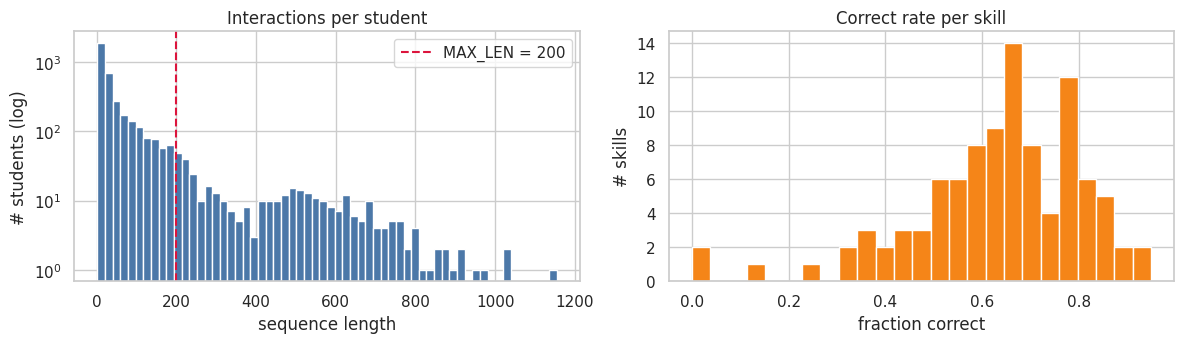

In [ ]:
seq_lens = data.groupby("user_id").size()
skill_rate = data.groupby("skill_idx")["correct"].mean()
overall_rate = data["correct"].mean()

print(f"Overall correct rate           : {overall_rate:.3f}  (always-guess-majority accuracy = {max(overall_rate, 1 - overall_rate):.3f})")
print(f"Interactions per student       : median {seq_lens.median():.0f} | 95th pct {seq_lens.quantile(0.95):.0f} | max {seq_lens.max():,}")
print(f"Students longer than MAX_LEN   : {(seq_lens > MAX_LEN).mean():.1%}  (these get cut into several windows)")
q_counts = data["question_idx"].value_counts()
print(f"Attempts per question          : median {q_counts.median():.0f} | questions with < 10 attempts: {(q_counts < 10).mean():.1%}  (their learned difficulty will be noisy)")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(seq_lens, bins=60, color="#4c78a8")
ax[0].set_yscale("log")
ax[0].axvline(MAX_LEN, color="crimson", ls="--", label=f"MAX_LEN = {MAX_LEN}")
ax[0].set(title="Interactions per student", xlabel="sequence length", ylabel="# students (log)")
ax[0].legend()
ax[1].hist(skill_rate, bins=25, color="#f58518")
ax[1].set(title="Correct rate per skill", xlabel="fraction correct", ylabel="# skills")
plt.tight_layout()
plt.show()

## 4. Splits and sequence windows

**Split by student.** If we split random *interactions*, the same student would appear in both train and test, and a model could score well just by memorising that student's habits. Splitting by student tests the thing we actually care about: *does the model generalise to people it has never seen?*

We use **80% train / 10% validation / 10% test** of students:
- **train**: fit the weights,
- **validation**: choose which epoch to keep (and spot overfitting),
- **test**: touched exactly once per model, at the very end.

**Windowing.** Students have wildly different history lengths. We cut each student's history into consecutive windows of at most `MAX_LEN = 200` interactions so batches are manageable. Two honest caveats: a window starts "cold" (it can't see earlier windows), and the first step of each window is never predicted because there's nothing before it.

In [ ]:
# Build each student's (skills, correctness) arrays once, then slice into windows per split.
user_seqs = {
    uid: (g["skill_idx"].to_numpy(), g["correct"].to_numpy(), g["question_idx"].to_numpy())
    for uid, g in data.groupby("user_id", sort=False)
}

def make_chunks(user_ids):
    chunks = []
    for uid in user_ids:
        s, c, q = user_seqs[uid]
        for i in range(0, len(s), MAX_LEN):
            s_ch, c_ch, q_ch = s[i:i + MAX_LEN], c[i:i + MAX_LEN], q[i:i + MAX_LEN]
            if len(s_ch) >= MIN_SEQ_LEN:
                chunks.append((s_ch, c_ch, q_ch))
    return chunks

rng = np.random.default_rng(SEED)
students = rng.permutation(data["user_id"].unique())
n_tr = int(SPLIT[0] * len(students))
n_va = int(SPLIT[1] * len(students))
train_ids, val_ids, test_ids = students[:n_tr], students[n_tr:n_tr + n_va], students[n_tr + n_va:]

# Safety check: no student may appear in two splits.
assert not (set(train_ids) & set(val_ids)) and not (set(train_ids) & set(test_ids)) and not (set(val_ids) & set(test_ids))

train_chunks, val_chunks, test_chunks = map(make_chunks, (train_ids, val_ids, test_ids))

summary = pd.DataFrame({
    "split": ["train", "val", "test"],
    "students": [len(train_ids), len(val_ids), len(test_ids)],
    "windows": [len(train_chunks), len(val_chunks), len(test_chunks)],
    "predictions": [sum(len(w[0]) - 1 for w in ch) for ch in (train_chunks, val_chunks, test_chunks)],
})
display(summary.style.format({"students": "{:,}", "windows": "{:,}", "predictions": "{:,}"}).hide(axis="index"))

split,students,windows,predictions
train,"3,157","3,678","232,638"
val,394,440,"24,785"
test,396,470,"30,176"


## 5. Batching: shifting by one step, and what each tensor means

Predicting step $t+1$ from steps $\le t$ means **inputs and targets are the same sequence shifted by one**. For a window of length $L$ we build six aligned tensors of length $L-1$:

| Tensor | Definition | Role |
|---|---|---|
| `ex` | skills $s_1..s_{L-1}$ | the skill of each past exercise |
| `ans` | $s_t + N\cdot c_t$ for $t=1..L-1$ | the past *interactions* (skill + outcome) |
| `target` | skills $s_2..s_L$ | the skill of the exercise we must predict |
| `y` | correctness $c_2..c_L$ | the label |
| `ex_q` | question IDs of steps $1..L-1$ | *which exact question* each past interaction was (used only by AKT (with Rasch)) |
| `tgt_q` | question IDs of steps $2..L$ | which exact question we must predict (used only by AKT (with Rasch)) |

**Worked example** with $N=3$ skills and a tiny history: skills `[2, 0, 2, 1]`, correct `[1, 0, 0, 1]`.

| position | `ex` | `ans` = skill + 3·correct | `target` | `y` |
|---|---|---|---|---|
| 0 | 2 | 2 + 3·1 = **5** | 0 | 0 |
| 1 | 0 | 0 + 3·0 = **0** | 2 | 0 |
| 2 | 2 | 2 + 3·0 = **2** | 1 | 1 |

Read row 0 as: *"after the student got skill 2 right, will they get skill 0 right? (they didn't, y = 0)"*.

Windows in a batch have different lengths, so we right-pad: skill tokens with `PAD_SKILL = N`, interaction tokens with `PAD_INTER = 2N`, and keep a boolean **`mask`** that is `True` on real steps. Loss and metrics use only masked-in positions.

**One collate function serves all models.** DKT's input is exactly `ans`, and its "which skill to read out" is `target`. The old notebook had two separate collators and six near-identical copies of the training loop.

In [ ]:
def collate(batch):
    ex, ans, tgt, y, m, exq, tgq = [], [], [], [], [], [], []
    for s, c, q in batch:
        s = s.astype(np.int64)
        c = c.astype(np.int64)
        q = q.astype(np.int64)
        exq.append(torch.as_tensor(q[:-1]))
        tgq.append(torch.as_tensor(q[1:]))
        ex.append(torch.as_tensor(s[:-1]))
        ans.append(torch.as_tensor(s[:-1] + N * c[:-1]))
        tgt.append(torch.as_tensor(s[1:]))
        y.append(torch.as_tensor(c[1:]).float())
        m.append(torch.ones(len(s) - 1, dtype=torch.bool))
    return (
        pad_sequence(ex,  batch_first=True, padding_value=PAD_SKILL),
        pad_sequence(ans, batch_first=True, padding_value=PAD_INTER),
        pad_sequence(tgt, batch_first=True, padding_value=PAD_SKILL),
        pad_sequence(y,   batch_first=True, padding_value=0.0),
        pad_sequence(m,   batch_first=True, padding_value=False),
        pad_sequence(exq, batch_first=True, padding_value=PAD_QUESTION),
        pad_sequence(tgq, batch_first=True, padding_value=PAD_QUESTION),
    )


def make_loader(chunks, train):
    # A fresh, seeded generator means every model sees the same shuffled batch order.
    g = torch.Generator().manual_seed(SEED)
    return DataLoader(chunks, batch_size=BATCH_TRAIN if train else BATCH_EVAL,
                      shuffle=train, collate_fn=collate, generator=g if train else None)


# Sanity check on real data: decode the first few steps of one window.
ex, ans, tgt, y, mask, ex_q, tgt_q = collate(train_chunks[:2])
print("batch shapes:", {k: tuple(v.shape) for k, v in zip(["ex", "ans", "target", "y", "mask", "ex_q", "tgt_q"], [ex, ans, tgt, y, mask, ex_q, tgt_q])})

s0, c0, q0 = train_chunks[0]
k = min(6, len(s0) - 1)
display(pd.DataFrame({
    "t": range(1, k + 1),
    "skill s_t": s0[:k],
    "question": q0[:k],
    "correct c_t": c0[:k],
    "ans = s_t + N*c_t": ans[0, :k].tolist(),
    "target (next skill)": tgt[0, :k].tolist(),
    "y (next correct)": y[0, :k].int().tolist(),
}).style.hide(axis="index"))

batch shapes: {'ex': (2, 199), 'ans': (2, 199), 'target': (2, 199), 'y': (2, 199), 'mask': (2, 199), 'ex_q': (2, 199), 'tgt_q': (2, 199)}


t,skill s_t,question,correct c_t,ans = s_t + N*c_t,target (next skill),y (next correct)
1,18,4234,1,117,15,0
2,15,3921,0,15,16,0
3,16,3921,0,16,15,0
4,15,3845,0,15,16,0
5,16,3845,0,16,15,1
6,15,3858,1,114,16,1


## 6. Model definitions

All models share one call signature, `model(ex, ans, target, mask, ex_q, tgt_q) -> logits` of shape `(batch, steps)`, so the same training code runs all of them. (Each model simply ignores the inputs it doesn't need; only AKT (with Rasch) reads the question IDs.)

### DKT: a recurrent network with a running "knowledge state"
Embed each interaction token, feed the sequence through an LSTM, and at every step output one logit **per skill** (how likely is the student to get *each* skill right next?). We read out the logit for the skill that actually comes next. This is the embedding-input variant of DKT (the original paper one-hot encodes the input).

**Three flavours of the recurrent cell** (the only thing that changes between the DKT variants):
- **Plain RNN:** rewrites one summary note after every answer. Simple, but on long histories early details get overwritten and training struggles to pass learning signal back that far (the vanishing-gradient problem).
- **LSTM:** adds *gates* that decide what to keep and what to forget, so important information (e.g. "keeps failing ratios") survives longer.
- **GRU:** a lighter cousin of the LSTM with fewer gates. Often matches it while being a bit faster.

### SAKT: look back with self-attention
No recurrent state. To predict step $t+1$, the **query** is the upcoming exercise's skill, and the **keys/values** are all past interactions. Attention weights say "which past interactions are relevant to this question?" (e.g. earlier attempts at the *same* skill). A causal mask stops position $t$ from seeing anything after $t$.

The `use_positions` switch adds a learned **positional embedding**. Without it, attention is blind to *when* things happened, since only the content of past interactions matters, not their order.

> **A note on padding masks.** The original notebook pitched a padding mask as an "improvement". With right-padding plus a causal mask, a real step can never attend to a padding position anyway (padding only sits *after* real steps), so the mask doesn't change any real prediction. It's kept as a harmless safety net. The meaningful ablation here is **positions on/off**.

### AKT: context-aware attentive knowledge tracing (full model)
Implemented following Ghosh et al. (2020) and the official code.

**1. Rasch embeddings.** Each question gets a scalar difficulty $\mu_q$ (initialised at 0, learned). The skill embedding is nudged by it:

$$x_t = c_{s_t} + \mu_{q_t}\cdot d_{s_t}, \qquad y_t = e_{(s_t,c_t)} + \mu_{q_t}\cdot f_{(s_t,c_t)}$$

where $c_s$ is the skill embedding, $d_s$ its "variation" vector, $e$ the (skill, outcome) embedding and $f$ its variation vector. `use_rasch=False` drops $\mu$ and gives the skill-only variant.

**2. Three attention modules.**
- **Question encoder:** self-attention over $x_1..x_t$ (may see the current question) giving $\hat{x}_t$.
- **Knowledge encoder:** self-attention over $y_1..y_t$ giving context-aware responses $\hat{y}_t$.
- **Knowledge retriever:** query = $\hat{x}_t$, keys = $\hat{x}_{1..t-1}$, values = $\hat{y}_{1..t-1}$. Strictly past, so the label can never leak.

**3. Monotonic attention with context-aware distance.** The score between steps $t$ and $\tau$ is multiplied by $e^{-\theta_h d(t,\tau)}$ with

$$d(t,\tau)=\sqrt{|t-\tau|\cdot\sum_{\tau'>\tau}\gamma_{t,\tau'}}, \qquad \theta_h=\text{softplus}(\vartheta_h)$$

where $\gamma_{t,\tau'}$ are the attention weights. So the decay depends not just on how long ago something happened but on how much *other* relevant practice sits in between. $\theta_h$ is learned per head; the distance itself is not back-propagated (as in the official code).

**4. Output.** Post-LayerNorm residual blocks with feed-forward layers (the question-encoder layer has none, as in the official code), then an MLP on `[retrieved ; raw question embedding]`. Query/key share one projection and there are no positional embeddings. A small L2 penalty on $\mu_q$ (`reg_loss`, 1e-5) is added to the loss.

**How it fits our batches.** Our tensors put the *next* question at each position, so `AKT.forward` rebuilds the paper's layout of length $L+1$ (questions for steps $1..L$, responses for steps $1..L-1$ plus one hidden pad) and drops the first output, which has no history.

> **Caveat.** Questions that appear only in validation/test (or very rarely in training) never get a trained $\mu_q$ and stay at 0 ("average"). The EDA prints how many questions have few attempts.
>
> **Differences from the paper's setup:** smaller default size (`d_model=128`, 8 heads, 1 block) and lr 1e-3 with early stopping, shared by all models here. Numbers will not match the paper exactly (different preprocessing and splits).


In [ ]:
class DKT(nn.Module):
    # rnn_type: "lstm" | "gru" | "rnn" -- the ONLY difference between the DKT variants.
    def __init__(self, n_skills, emb_size=64, hidden_size=128, rnn_type="lstm"):
        super().__init__()
        self.n_skills = n_skills
        self.emb = nn.Embedding(2 * n_skills + 1, emb_size, padding_idx=2 * n_skills)
        rnn_cls = {"lstm": nn.LSTM, "gru": nn.GRU, "rnn": nn.RNN}[rnn_type]
        self.rnn = rnn_cls(emb_size, hidden_size, batch_first=True)
        self.out = nn.Linear(hidden_size, n_skills)

    def forward(self, ex, ans, target, mask=None, ex_q=None, tgt_q=None):
        h, _ = self.rnn(self.emb(ans))                     # (B, L, hidden)
        all_skill_logits = self.out(h)                      # (B, L, N): one logit per skill
        # Padding positions carry target == N (out of range); clamp them, they are masked out of the loss anyway.
        idx = target.clamp(max=self.n_skills - 1).unsqueeze(-1)
        return all_skill_logits.gather(2, idx).squeeze(-1)  # (B, L): logit for the skill that comes next


class SAKT(nn.Module):
    def __init__(self, n_skills, emb_size=64, num_heads=4, dropout=0.2,
                 max_len=MAX_LEN, use_positions=False):
        super().__init__()
        self.item_emb = nn.Embedding(n_skills + 1, emb_size, padding_idx=n_skills)
        self.interaction_emb = nn.Embedding(2 * n_skills + 1, emb_size, padding_idx=2 * n_skills)
        self.pos_emb = nn.Embedding(max_len, emb_size) if use_positions else None
        self.attn = nn.MultiheadAttention(emb_size, num_heads, dropout=dropout, batch_first=True)
        self.ffn = nn.Sequential(
            nn.Linear(emb_size, emb_size), nn.ReLU(),
            nn.Dropout(dropout), nn.Linear(emb_size, emb_size),
        )
        self.ln1 = nn.LayerNorm(emb_size)
        self.ln2 = nn.LayerNorm(emb_size)
        self.pred = nn.Linear(emb_size, 1)

    def forward(self, ex, ans, target, mask=None, ex_q=None, tgt_q=None):
        L = ex.size(1)
        causal = torch.triu(torch.ones(L, L, dtype=torch.bool, device=ex.device), diagonal=1)  # True = blocked
        q = self.item_emb(target)            # query: the exercise we must predict
        kv = self.interaction_emb(ans)       # keys/values: past (skill, outcome) interactions
        if self.pos_emb is not None:
            p = self.pos_emb(torch.arange(L, device=ex.device)).unsqueeze(0)
            q, kv = q + p, kv + p
        key_padding = None if mask is None else ~mask       # True = padding
        a, _ = self.attn(q, kv, kv, attn_mask=causal, key_padding_mask=key_padding, need_weights=False)
        x = self.ln1(q + a)
        return self.pred(self.ln2(x + self.ffn(x))).squeeze(-1)


# ----- Full AKT (Ghosh et al., 2020): see markdown above for the exact ingredients -----
class MonotonicAttention(nn.Module):
    """Multi-head attention with the context-aware exponential decay of AKT."""

    def __init__(self, d_model, n_heads, dropout=0.1, kq_same=True):
        super().__init__()
        assert d_model % n_heads == 0
        self.h, self.dk = n_heads, d_model // n_heads
        self.k_lin = nn.Linear(d_model, d_model)
        self.q_lin = self.k_lin if kq_same else nn.Linear(d_model, d_model)
        self.v_lin = nn.Linear(d_model, d_model)
        self.out_lin = nn.Linear(d_model, d_model)
        self.drop = nn.Dropout(dropout)
        # gamma_h; theta_h = softplus(gamma_h) >= 0 is the per-head decay rate
        self.gammas = nn.Parameter(torch.zeros(n_heads, 1, 1))
        nn.init.xavier_uniform_(self.gammas)

    @property
    def decay(self):
        return F.softplus(self.gammas).view(-1)

    def forward(self, q, k, v, allow_diagonal, zero_pad=False):
        B, L, _ = q.shape
        split = lambda x: x.view(B, L, self.h, self.dk).transpose(1, 2)       # (B, h, L, dk)
        q_, k_, v_ = split(self.q_lin(q)), split(self.k_lin(k)), split(self.v_lin(v))
        scores = torch.matmul(q_, k_.transpose(-1, -2)) / math.sqrt(self.dk)   # (B, h, L, L)

        idx = torch.arange(L, device=q.device)
        i, j = idx.unsqueeze(1), idx.unsqueeze(0)
        allowed = (j <= i) if allow_diagonal else (j < i)                      # causal mask

        with torch.no_grad():                                                  # distance is not back-propagated
            s = torch.softmax(scores.masked_fill(~allowed, -1e32), dim=-1) * allowed
            dist_cum = s.cumsum(dim=-1)                                        # mass up to and incl. tau
            dist_total = s.sum(dim=-1, keepdim=True)
            remaining = dist_total - dist_cum                                  # mass strictly after tau
            dist = (remaining * (i - j).abs().float()).clamp(min=0).sqrt()     # d(t, tau)

        theta = F.softplus(self.gammas)                                        # (h, 1, 1)
        effect = torch.exp(-theta * dist).clamp(1e-5, 1e5)                     # exp(-theta * d)
        scores = (scores * effect).masked_fill(~allowed, -1e32)
        w = torch.softmax(scores, dim=-1)
        if zero_pad:                                                           # first step has no past at all
            w = torch.cat([torch.zeros_like(w[:, :, :1]), w[:, :, 1:]], dim=2)
        w = self.drop(w)
        out = torch.matmul(w, v_).transpose(1, 2).reshape(B, L, -1)
        return self.out_lin(out)


class AKTBlock(nn.Module):
    """Attention + residual + LayerNorm, optionally followed by FFN + residual + LayerNorm."""

    def __init__(self, d_model, d_ff, n_heads, dropout, kq_same, use_ffn):
        super().__init__()
        self.attn = MonotonicAttention(d_model, n_heads, dropout, kq_same)
        self.ln1 = nn.LayerNorm(d_model)
        self.drop1 = nn.Dropout(dropout)
        self.use_ffn = use_ffn
        if use_ffn:
            self.ffn = nn.Sequential(nn.Linear(d_model, d_ff), nn.ReLU(), nn.Dropout(dropout),
                                     nn.Linear(d_ff, d_model))
            self.ln2 = nn.LayerNorm(d_model)
            self.drop2 = nn.Dropout(dropout)

    def forward(self, q, k, v, allow_diagonal, zero_pad=False):
        x = self.ln1(q + self.drop1(self.attn(q, k, v, allow_diagonal, zero_pad)))
        if self.use_ffn:
            x = self.ln2(x + self.drop2(self.ffn(x)))
        return x


class AKT(nn.Module):
    """
    use_rasch=False -> concept-only AKT (no question difficulty), needs only skill ids.
    use_rasch=True  -> full AKT with Rasch question difficulty.
    n_blocks        -> number of (question-encoder, retriever) pairs; knowledge encoder gets n_blocks layers.
    """

    def __init__(self, n_skills, n_questions=0, d_model=128, n_heads=8, d_ff=256, n_blocks=1,
                 dropout=0.1, fc_dim=256, kq_same=True, use_rasch=True, l2=1e-5):
        super().__init__()
        self.n_skills, self.n_questions = n_skills, n_questions
        self.use_rasch, self.l2 = use_rasch, l2

        self.item_emb = nn.Embedding(n_skills + 1, d_model, padding_idx=n_skills)             # c_s
        self.inter_emb = nn.Embedding(2 * n_skills + 1, d_model, padding_idx=2 * n_skills)    # e_(s,c)
        if use_rasch:
            self.item_var = nn.Embedding(n_skills + 1, d_model, padding_idx=n_skills)         # d_s
            self.inter_var = nn.Embedding(2 * n_skills + 1, d_model, padding_idx=2 * n_skills)  # f_(s,c)
            self.difficulty = nn.Embedding(n_questions + 1, 1, padding_idx=n_questions)       # mu_q

        self.know_enc = nn.ModuleList(            # y -> y^        (sees steps <= t)
            [AKTBlock(d_model, d_ff, n_heads, dropout, kq_same, use_ffn=True) for _ in range(n_blocks)])
        self.ques_enc = nn.ModuleList(            # x -> x^        (sees steps <= t, no FFN as in official code)
            [AKTBlock(d_model, d_ff, n_heads, dropout, kq_same, use_ffn=False) for _ in range(n_blocks)])
        self.retriever = nn.ModuleList(           # (x^, x^, y^)   (sees steps <  t)
            [AKTBlock(d_model, d_ff, n_heads, dropout, kq_same, use_ffn=True) for _ in range(n_blocks)])

        self.head = nn.Sequential(
            nn.Linear(2 * d_model, fc_dim), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(fc_dim, fc_dim // 2), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(fc_dim // 2, 1))
        self._reset()

    def _reset(self):
        for name, p in self.named_parameters():
            if p.dim() > 1 and "gammas" not in name:
                nn.init.xavier_uniform_(p)
        with torch.no_grad():
            for emb in (self.item_emb, self.inter_emb):
                emb.weight[emb.padding_idx].zero_()
            if self.use_rasch:
                self.difficulty.weight.zero_()          # every question starts at "average" difficulty
                for emb in (self.item_var, self.inter_var):
                    emb.weight[emb.padding_idx].zero_()

    @property
    def decay(self):
        """Learned theta per head, all attention layers concatenated (notebook prints .mean())."""
        mods = [b.attn for b in (*self.know_enc, *self.ques_enc, *self.retriever)]
        return torch.cat([m.decay for m in mods])

    def reg_loss(self):
        """L2 penalty on Rasch difficulties (official AKT: 1e-5 * sum(mu^2)). Add to the BCE loss."""
        if not self.use_rasch:
            return torch.zeros((), device=self.item_emb.weight.device)
        return self.l2 * (self.difficulty.weight ** 2).sum()

    def forward(self, ex, ans, target, mask=None, ex_q=None, tgt_q=None):
        # Notebook layout: position i holds past step i (ex, ans) and the NEXT step's question (target).
        # Rebuild the official AKT layout of length T = L+1 (steps 1..L):
        #   questions : [ex_0, target_0, ..., target_{L-1}]       (step 1, then steps 2..L)
        #   responses : [ans_0, ..., ans_{L-1}, <pad>]            (response of step L is the label -> hidden)
        B, L = ex.shape
        pad_inter = 2 * self.n_skills
        s_full = torch.cat([ex[:, :1], target], dim=1)                                     # (B, L+1)
        a_full = torch.cat([ans, torch.full((B, 1), pad_inter, dtype=ans.dtype, device=ans.device)], dim=1)

        x = self.item_emb(s_full)
        y = self.inter_emb(a_full)
        if self.use_rasch:
            q_full = torch.cat([ex_q[:, :1], tgt_q], dim=1)
            mu = self.difficulty(q_full)                                                   # (B, L+1, 1)
            x = x + mu * self.item_var(s_full)                                             # x_t = c_s + mu_q d_s
            y = y + mu * self.inter_var(a_full)                                            # y_t = e_(s,c) + mu_q f_(s,c)
        x_raw = x

        for blk in self.know_enc:                                                          # knowledge encoder
            y = blk(y, y, y, allow_diagonal=True)
        for q_blk, r_blk in zip(self.ques_enc, self.retriever):
            x = q_blk(x, x, x, allow_diagonal=True)                                        # question encoder
            x = r_blk(x, x, y, allow_diagonal=False, zero_pad=True)                        # knowledge retriever

        h = torch.cat([x, x_raw], dim=-1)[:, 1:]                                           # drop step 1 (no history)
        return self.head(h).squeeze(-1)                                                    # (B, L)


def count_params(m):
    return sum(p.numel() for p in m.parameters() if p.requires_grad)

MODEL_ZOO = {
    "DKT (LSTM)":       lambda: DKT(N, rnn_type="lstm"),
    "DKT (GRU)":        lambda: DKT(N, rnn_type="gru"),
    "DKT (RNN)":        lambda: DKT(N, rnn_type="rnn"),
    "SAKT":             lambda: SAKT(N, use_positions=False),
    "SAKT + positions": lambda: SAKT(N, use_positions=True),
    "AKT (no Rasch)":   lambda: AKT(N, use_rasch=False),
    "AKT":              lambda: AKT(N, n_questions=Q, use_rasch=True),
}
for name, build in MODEL_ZOO.items():
    print(f"{name:<18} {count_params(build()):>10,} trainable parameters")

DKT (LSTM)            124,835 trainable parameters
DKT (GRU)             100,003 trainable parameters
DKT (RNN)              50,339 trainable parameters
SAKT                   44,417 trainable parameters
SAKT + positions       57,217 trainable parameters
AKT (no Rasch)        418,841 trainable parameters
AKT                   471,537 trainable parameters


## 7. Training engine

One `fit()` function trains any model from the zoo:

- **Loss:** `BCEWithLogitsLoss` computed only on real (`mask == True`) steps.
- **Optimiser:** Adam, `lr = 1e-3`; gradient norm clipped at 5 (keeps the LSTM stable).
- **Model selection:** after each epoch, compute **validation AUC**; keep a copy of the weights from the best epoch and restore them at the end. So the test set is evaluated with the *best-validation* model, not whichever epoch happened to be last.
- **Fairness:** `set_seed()` before each model, and the training loader reuses the same seeded shuffle, so all models see identical batches in identical order.

In [ ]:
loss_fn = nn.BCEWithLogitsLoss()


def to_device(batch):
    return [t.to(device) for t in batch]


def train_one_epoch(model, loader, optimizer):
    model.train()
    total_loss, total_steps = 0.0, 0
    for batch in loader:
        ex, ans, tgt, y, mask, ex_q, tgt_q = to_device(batch)
        logits = model(ex, ans, tgt, mask, ex_q, tgt_q)
        loss = loss_fn(logits[mask], y[mask])
        if hasattr(model, "reg_loss"):
            loss = loss + model.reg_loss()      # AKT: L2 on Rasch difficulties (zero for other models)
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        optimizer.step()
        n = int(mask.sum())
        total_loss += loss.item() * n
        total_steps += n
    return total_loss / total_steps


@torch.no_grad()
def predict(model, loader):
    # Returns flat (labels, probabilities) over all real prediction steps.
    model.eval()
    labels, probs = [], []
    for batch in loader:
        ex, ans, tgt, y, mask, ex_q, tgt_q = to_device(batch)
        p = torch.sigmoid(model(ex, ans, tgt, mask, ex_q, tgt_q))
        labels.append(y[mask].cpu().numpy())
        probs.append(p[mask].cpu().numpy())
    return np.concatenate(labels), np.concatenate(probs)


def fit(name, model, train_loader, val_loader, epochs=EPOCHS):
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)
    history = {"train_loss": [], "val_auc": []}
    best_auc, best_epoch, best_state = -1.0, 0, None

    for epoch in range(1, epochs + 1):
        t0 = time.time()
        loss = train_one_epoch(model, train_loader, optimizer)
        yv, pv = predict(model, val_loader)
        auc = roc_auc_score(yv, pv)
        history["train_loss"].append(loss)
        history["val_auc"].append(auc)
        if auc > best_auc:
            best_auc, best_epoch = auc, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        print(f"{name:<18} epoch {epoch:2d}/{epochs} | train loss {loss:.4f} | val AUC {auc:.4f} | {time.time() - t0:5.1f}s")
        if epoch - best_epoch >= PATIENCE:
            print(f"{name:<18} early stop: no val-AUC gain for {PATIENCE} epochs")
            break

    model.load_state_dict(best_state)   # restore best-validation weights
    return history, best_epoch, best_auc

## 8. Run all experiments

For each model: train with early model-selection on validation, then score the **test** set once with the restored best weights. Test predictions are stored so the plots below don't have to re-run anything.

In [ ]:
val_loader = make_loader(val_chunks, train=False)
test_loader = make_loader(test_chunks, train=False)

results = {}
for name, build in MODEL_ZOO.items():
    print(f"\n=== {name} ===")
    set_seed(SEED)                                   # same init seed for every model
    model = build()
    train_loader = make_loader(train_chunks, train=True)   # same batch order for every model
    history, best_epoch, best_val_auc = fit(name, model, train_loader, val_loader)

    y_test, p_test = predict(model, test_loader)
    results[name] = {
        "history": history, "best_epoch": best_epoch, "val_auc": best_val_auc,
        "y_test": y_test, "p_test": p_test, "n_params": count_params(model),
        "state": {k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
    }
    if isinstance(model, AKT):
        print(f"learned decay theta = {model.decay.mean().item():.4f} (mean over all heads/layers; theta = softplus(gamma))")
    print(f"-> best epoch {best_epoch} | val AUC {best_val_auc:.4f} | TEST AUC {roc_auc_score(y_test, p_test):.4f}")


=== DKT (LSTM) ===
DKT (LSTM)         epoch  1/60 | train loss 0.5851 | val AUC 0.7879 |   2.5s
DKT (LSTM)         epoch  2/60 | train loss 0.4859 | val AUC 0.8134 |   2.2s
DKT (LSTM)         epoch  3/60 | train loss 0.4613 | val AUC 0.8162 |   3.0s
DKT (LSTM)         epoch  4/60 | train loss 0.4522 | val AUC 0.8215 |   1.7s
DKT (LSTM)         epoch  5/60 | train loss 0.4461 | val AUC 0.8215 |   1.7s
DKT (LSTM)         epoch  6/60 | train loss 0.4416 | val AUC 0.8225 |   1.5s
DKT (LSTM)         epoch  7/60 | train loss 0.4382 | val AUC 0.8230 |   1.1s
DKT (LSTM)         epoch  8/60 | train loss 0.4345 | val AUC 0.8239 |   1.2s
DKT (LSTM)         epoch  9/60 | train loss 0.4317 | val AUC 0.8250 |   0.8s
DKT (LSTM)         epoch 10/60 | train loss 0.4291 | val AUC 0.8241 |   0.7s
DKT (LSTM)         epoch 11/60 | train loss 0.4264 | val AUC 0.8233 |   0.6s
DKT (LSTM)         epoch 12/60 | train loss 0.4242 | val AUC 0.8235 |   0.6s
DKT (LSTM)         epoch 13/60 | train loss 0.4212 | val

## 9. Results

**Metrics.** AUC is the headline. Accuracy / precision / recall / F1 use a fixed 0.5 threshold, so they depend on how the model is calibrated and how imbalanced the labels are, which is why the **majority-class baseline** is shown next to them.

In [ ]:
def summarise(y, p, threshold=0.5):
    pred = (p >= threshold).astype(int)
    return {
        "Test AUC": roc_auc_score(y, p),
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
    }

rows = []
for name, r in results.items():
    rows.append({"Model": name, "Params": r["n_params"], "Best epoch": r["best_epoch"],
                 "Val AUC": r["val_auc"], **summarise(r["y_test"], r["p_test"])})
results_df = pd.DataFrame(rows)

y_ref = next(iter(results.values()))["y_test"]       # identical test labels for every model
base_acc = max(y_ref.mean(), 1 - y_ref.mean())

fmt = {"Params": "{:,}", "Val AUC": "{:.4f}", "Test AUC": "{:.4f}", "Accuracy": "{:.4f}",
       "Precision": "{:.4f}", "Recall": "{:.4f}", "F1": "{:.4f}"}
display(results_df.style.format(fmt).hide(axis="index")
        .highlight_max(subset=["Test AUC", "Accuracy", "F1"], color="#cde8cd"))
print(f"Majority-class baseline: accuracy = {base_acc:.4f}, AUC = 0.5000   (n test predictions = {len(y_ref):,})")

Model,Params,Best epoch,Val AUC,Test AUC,Accuracy,Precision,Recall,F1
DKT (LSTM),"124,835",9,0.8250,0.8327,0.7822,0.7889,0.9161,0.8478
DKT (GRU),"100,003",13,0.8276,0.8343,0.7840,0.7893,0.9189,0.8492
DKT (RNN),"50,339",14,0.8239,0.8307,0.7801,0.7903,0.9091,0.8455
SAKT,"44,417",59,0.7687,0.7710,0.7408,0.7529,0.9055,0.8222
SAKT + positions,"57,217",32,0.8007,0.8059,0.7629,0.7752,0.9039,0.8346
AKT (no Rasch),"418,841",20,0.8272,0.8315,0.7792,0.7909,0.9059,0.8445
AKT,"471,537",15,0.8383,0.8407,0.7835,0.8070,0.8845,0.8439


Majority-class baseline: accuracy = 0.6619, AUC = 0.5000   (n test predictions = 30,176)


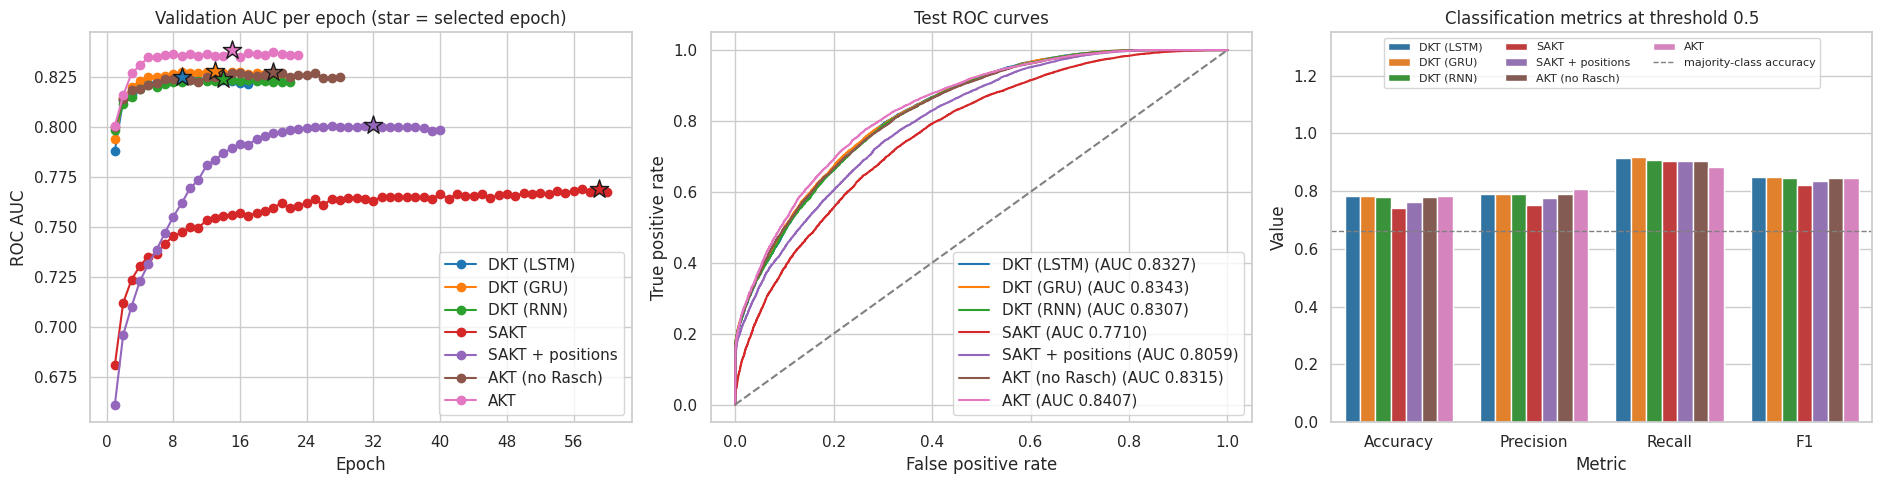

Best test AUC: AKT (0.8407), +0.0064 ahead of DKT (GRU).


In [ ]:
palette = dict(zip(results, sns.color_palette("tab10", len(results))))
fig, axes = plt.subplots(1, 3, figsize=(19, 5))

# (1) Validation learning curves, with the selected epoch starred.
for name, r in results.items():
    ep = range(1, len(r["history"]["val_auc"]) + 1)
    axes[0].plot(ep, r["history"]["val_auc"], marker="o", label=name, color=palette[name])
    axes[0].scatter(r["best_epoch"], r["val_auc"], s=190, marker="*", color=palette[name], edgecolor="k", zorder=5)
axes[0].set(title="Validation AUC per epoch (star = selected epoch)", xlabel="Epoch", ylabel="ROC AUC")
axes[0].xaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].legend()

# (2) ROC curves on the held-out test students.
for name, r in results.items():
    fpr, tpr, _ = roc_curve(r["y_test"], r["p_test"])
    axes[1].plot(fpr, tpr, color=palette[name], label=f"{name} (AUC {roc_auc_score(r['y_test'], r['p_test']):.4f})")
axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set(title="Test ROC curves", xlabel="False positive rate", ylabel="True positive rate")
axes[1].legend(loc="lower right")

# (3) Threshold-0.5 metrics side by side.
long_df = results_df.melt(id_vars="Model", value_vars=["Accuracy", "Precision", "Recall", "F1"],
                          var_name="Metric", value_name="Value")
sns.barplot(data=long_df, x="Metric", y="Value", hue="Model", palette=palette, ax=axes[2])
axes[2].axhline(base_acc, color="gray", ls="--", lw=1, label="majority-class accuracy")
axes[2].set(title="Classification metrics at threshold 0.5", ylim=(0, 1.35))
axes[2].legend(fontsize=8, loc="upper center", ncol=3)

plt.tight_layout()
plt.show()

ranked = results_df.sort_values("Test AUC", ascending=False).reset_index(drop=True)
gap = ranked.loc[0, "Test AUC"] - ranked.loc[1, "Test AUC"]
print(f"Best test AUC: {ranked.loc[0, 'Model']} ({ranked.loc[0, 'Test AUC']:.4f}), "
      f"{gap:+.4f} ahead of {ranked.loc[1, 'Model']}.")

In [ ]:
import torch
from google.colab import files

# Save the best-validation weights for each model and trigger the browser download
for name, r in results.items():
    # Replace spaces/special characters for safe filenames
    safe_name = name.lower().replace(" ", "_").replace("+", "plus")
    filename = f"{safe_name}_best_weights.pt"

    state_dict = r["state"]   # best-validation weights stored in section 8
    torch.save(state_dict, filename)
    print(f"Saved {filename}")

    # Trigger browser download
    files.download(filename)


Saved dkt_(lstm)_best_weights.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved dkt_(gru)_best_weights.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (11 outputs left out)

<IPython.core.display.Javascript object>

Saved akt_best_weights.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. How to read these results, and what they can't tell you

**Questions the setup is built to answer**
1. **DKT vs the attention models.** Does look-back attention beat a single recurrent state on this data?
2. **SAKT vs SAKT + positions.** Same model, only positional embeddings differ, so the gap is the value of knowing *when* things happened.
3. **SAKT vs AKT (no Rasch).** Both skill-only attention models; AKT adds the encoders and context-aware decay. The printed mean $\theta$ says how strongly the model learned to discount old practice: near 0 means "recency doesn't matter much", larger means "recent practice dominates".
4. **AKT (no Rasch) vs AKT.** Identical except for per-question difficulty, so the gap is *exactly* what knowing which question was asked is worth. If it's small, either skills already explain most of the difficulty here, or many questions have too few attempts to learn a reliable $\mu_q$.
5. **Val vs test AUC.** A small gap means the epoch selection generalised. A big one means you've overfit to the validation students.
6. **LSTM vs GRU vs plain RNN.** Same DKT, same data, same seed; only the memory cell differs. Expect the plain RNN to be the weakest on long histories and the LSTM and GRU to be close. If all three land within about 0.005 AUC, call it a tie and prefer the cheapest (usually GRU or RNN).

**Things to keep in mind**
- **Single run, single seed.** Differences of a few thousandths of AUC are well within run-to-run noise. Treat small gaps as ties. For a firmer claim, repeat over several seeds / student splits and report mean ± std.
- **Compare within this notebook, not against papers.** Published ASSISTments 2009 numbers vary a lot with preprocessing (multi-skill handling, split style, windowing). An unusually high AUC here is a red flag worth investigating (leakage is the usual cause).
- **Only AKT (with Rasch) sees individual questions.** DKT, SAKT and AKT (no Rasch) see skill IDs only, so comparing AKT with them mixes "better architecture" with "extra information". The clean comparison for the effect of difficulty is AKT (no Rasch) vs AKT. None of the models use timestamps.
- **Multi-skill rows.** The data processing keeps one row per `(order_id, skill_id)` (as in the first notebook), so a problem tagged with several skills appears as several consecutive rows with the same correctness. A model can use the answer to one row to predict the next, which likely makes AUC optimistic.
- **Windowing** resets history every `MAX_LEN` steps, which slightly handicaps every model, and long-history students most.
- **Check convergence.** If a model's *best epoch is the last epoch*, it was still improving when training stopped, so the comparison is partly "who learns fastest". AKT with Rasch is the clear case: every question's difficulty starts at 0 and has to be learned, so it can look flat for several epochs and then climb. If you see this in the results table, raise `EPOCHS` (it's cheap for the AKT models) and re-run.
- **No tuning.** Hyperparameters are the same for every model and untuned, so the ranking reflects "reasonable defaults", not each model's ceiling.

**Natural next steps**
- Add **BKT** as a classical baseline (it's discussed in the literature but not implemented here).
- Run 3 to 5 seeds and report confidence intervals.
- Give DKT and SAKT the question IDs too (e.g. as an extra embedding) for a like-for-like comparison with AKT (with Rasch).
- Try `n_blocks=2` or the paper's larger sizes (`d_model=256`, lower lr) for AKT.
- Compare against a variant that keeps one row per `order_id`, to *measure* how much multi-skill rows inflate AUC.

## References

1. Piech, C., Bassen, J., Huang, J., Ganguli, S., Sahami, M., Guibas, L. J., & Sohl-Dickstein, J. (2015). Deep knowledge tracing. *Advances in Neural Information Processing Systems 28 (NeurIPS 2015)*, 505-513.
2. Pandey, S., & Karypis, G. (2019). A self-attentive model for knowledge tracing. *Proceedings of the 12th International Conference on Educational Data Mining (EDM 2019)*, 384-389.
3. Ghosh, A., Heffernan, N., & Lan, A. S. (2020). Context-aware attentive knowledge tracing. *Proceedings of the 26th ACM SIGKDD International Conference on Knowledge Discovery & Data Mining (KDD 2020)*, 2330-2339.
4. Corbett, A. T., & Anderson, J. R. (1994). Knowledge tracing: Modeling the acquisition of procedural knowledge. *User Modeling and User-Adapted Interaction, 4*(4), 253-278.
5. Feng, M., Heffernan, N., & Koedinger, K. (2009). Addressing the assessment challenge with an online system that tutors as it assesses. *User Modeling and User-Adapted Interaction, 19*(3), 243-266. *(the ASSISTments system / dataset source)*